# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/suyashverma0/flyrank-ml-workspace2/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

In [1]:
import pandas as pd
from pathlib import Path
import subprocess

repo_path = Path("/content/flyrank-ml-workspace2")

if not repo_path.exists():
    subprocess.run([
        "git", "clone",
        "https://github.com/suyashverma0/flyrank-ml-workspace2.git",
        str(repo_path)
    ], check=True)

matches = list(repo_path.rglob("content_refresh_anonymized.csv"))

if not matches:
    raise FileNotFoundError("Dataset CSV nahi mili.")

data_path = matches[0]
df = pd.read_csv(data_path)

print("Dataset loaded:", df.shape)
display(df.head())

Dataset loaded: (30000, 44)


,content_id,client_id,search_volume,competition,competition_level,cpc,content_type,main_intent,word_count,char_count,...,char_count_tier,ctr,avg_position,engagement_rate,scroll_rate,ai_traffic_pct,impression_tier,position_tier,trend_direction,trend_pct
0,content_304f48230142,client_f369cb89fc,10.0,0.67,HIGH,2.05,keyword article,transactional,3221.0,20457.0,...,15000-25000,0.76,10.6,5.88,4.55,0.0,good,striking,down,-41.4
1,content_a1fb4e703a9e,client_4e07408562,90.0,0.01,LOW,0.05,keyword article,informational,2481.0,15562.0,...,15000-25000,0.05,20.3,0.00,10.00,0.0,good,page_3_5,down,-57.7
2,content_9aa793d4d895,client_7f2253d7e2,0.0,0.00,LOW,0.00,keyword article,informational,3515.0,23643.0,...,15000-25000,0.09,36.5,0.00,28.57,0.0,good,page_3_5,down,-60.9
3,content_331d6c4de07b,client_19581e27de,10.0,0.00,LOW,0.00,keyword article,commercial,NaN,NaN,...,NaN,0.49,6.2,1.28,3.45,0.0,good,page_1,stable,-13.8
4,content_d99b7a2d90ca,client_3fdba35f04,0.0,0.00,LOW,0.00,keyword article,informational,2803.0,17469.0,...,15000-25000,0.13,44.0,0.00,24.29,0.0,good,page_3_5,down,-34.7


In [2]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

# Check that dataset is loaded
print("Dataset shape:", df.shape)

# Target: historical declining proxy
df = df.copy()
df["is_declining_proxy"] = (
    df["trend_direction"].astype(str).str.lower() == "down"
).astype(int)

# Metadata-only model features
numeric_features = [
    "search_volume",
    "competition",
    "cpc",
    "word_count",
    "char_count",
    "content_age_days",
    "days_since_last_update"
]

categorical_features = [
    "competition_level",
    "content_type",
    "main_intent"
]

feature_columns = numeric_features + categorical_features

X = df[feature_columns].copy()
y = df["is_declining_proxy"].copy()
groups = df["client_id"].copy()

for col in numeric_features:
    X[col] = pd.to_numeric(X[col], errors="coerce")

# Client-grouped train/test split
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]
y_train = y.iloc[train_idx]

train_clients = set(groups.iloc[train_idx])
test_clients = set(groups.iloc[test_idx])

assert train_clients.isdisjoint(test_clients)

# Preprocessing and model
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

playbook_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

playbook_model.fit(X_train, y_train)

# Score only held-out clients
queue = df.iloc[test_idx].copy()
queue["model_score"] = playbook_model.predict_proba(X_test)[:, 1]

# Reason-code thresholds calculated from training data only
train_rows = df.iloc[train_idx]

ctr_threshold = pd.to_numeric(
    train_rows["ctr"], errors="coerce"
).quantile(0.25)

engagement_threshold = pd.to_numeric(
    train_rows["engagement_rate"], errors="coerce"
).quantile(0.25)

# Add human-readable reason codes
def get_reason_codes(row):
    reasons = []

    ctr = pd.to_numeric(
        pd.Series([row.get("ctr")]), errors="coerce"
    ).iloc[0]

    engagement = pd.to_numeric(
        pd.Series([row.get("engagement_rate")]), errors="coerce"
    ).iloc[0]

    age = pd.to_numeric(
        pd.Series([row.get("days_since_last_update")]), errors="coerce"
    ).iloc[0]

    position = pd.to_numeric(
        pd.Series([row.get("avg_position")]), errors="coerce"
    ).iloc[0]

    if pd.notna(ctr) and ctr <= ctr_threshold:
        reasons.append("Low CTR")

    if pd.notna(engagement) and engagement <= engagement_threshold:
        reasons.append("Low engagement")

    if pd.notna(age) and age >= 180:
        reasons.append("Not updated for 180+ days")

    if pd.notna(position) and position > 20:
        reasons.append("Weak average position")

    return "; ".join(reasons) if reasons else "No listed warning signal"

queue["reason_codes"] = queue.apply(get_reason_codes, axis=1)

# Rank by model score
queue = queue.sort_values(
    "model_score",
    ascending=False
).reset_index(drop=True)

queue.insert(0, "priority_rank", range(1, len(queue) + 1))

# Keep only useful queue columns
queue_columns = [
    "priority_rank",
    "content_id",
    "model_score",
    "reason_codes",
    "ctr",
    "engagement_rate",
    "days_since_last_update",
    "avg_position"
]

queue = queue[
    [col for col in queue_columns if col in queue.columns]
]

print("Queue size:", len(queue))
display(queue.head(20))

Dataset shape: (30000, 44)
Queue size: 7115


,priority_rank,content_id,model_score,reason_codes,ctr,engagement_rate,days_since_last_update,avg_position
0,1,content_dd3e4df749a3,0.781510,Low CTR; Low engagement,0.00,0.0,20,2.1
1,2,content_7107cf349e26,0.780387,Low CTR; Low engagement,0.00,0.0,20,4.3
2,3,content_2ceef0464663,0.779159,Low CTR; Low engagement,0.00,0.0,20,1.6
3,4,content_49001e07f686,0.778995,Low engagement,4.70,0.0,20,5.5
4,5,content_1ff47abbc82b,0.778724,Low CTR; Low engagement,0.00,0.0,20,4.7
5,6,content_b7a310a51128,0.778211,Low engagement,1.25,0.0,20,11.6
6,7,content_09f654d4117a,0.778157,Low engagement; Weak average position,4.00,0.0,20,22.7
7,8,content_0a631257482b,0.778138,Low engagement,1.75,0.0,20,2.1
8,9,content_0f2016e46347,0.778071,Low CTR; Low engagement,0.00,0.0,20,0.0
9,10,content_8734ef61fd7b,0.777762,Low CTR; Low engagement,0.00,0.0,20,9.1


## 2. Intended use and limits

*Who uses this, for what — and where it stops being valid.*

In [3]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
print("Intended use: prioritize content for human review")
print("Scored items:", len(queue))
print("Model score range:",
      round(queue["model_score"].min(), 4),
      "to",
      round(queue["model_score"].max(), 4))

print("\nReason-code frequency:")
display(
    queue["reason_codes"]
    .value_counts()
    .rename_axis("reason_code")
    .reset_index(name="item_count")
)

print("\nReminder: scores are decision-support signals, not guarantees.")

Intended use: prioritize content for human review
Scored items: 7115
Model score range: 0.0924 to 0.7815

Reason-code frequency:


,reason_code,item_count
0,Low CTR; Low engagement,2693
1,Low engagement,1610
2,No listed warning signal,1045
3,Low CTR; Low engagement; Weak average position,946
4,Low engagement; Weak average position,455
5,Weak average position,191
6,Low CTR,75
7,Low CTR; Weak average position,53
8,Low CTR; Low engagement; Not updated for 180+ ...,34
9,Low engagement; Not updated for 180+ days,7



Reminder: scores are decision-support signals, not guarantees.


## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*

In [4]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
# Human-review checklist for the highest-priority items
review_sample = queue.head(20).copy()

review_sample["content_relevance_checked"] = False
review_sample["search_intent_checked"] = False
review_sample["data_quality_checked"] = False
review_sample["human_decision"] = "Pending review"

display(review_sample)

# No-go checks
no_go_actions = [
    "Automatic deletion",
    "Automatic rewriting or publishing",
    "Automatic URL redirects",
    "Guaranteeing ranking or traffic improvements",
    "Taking action using model score alone"
]

print("Actions that must not be automated:")
for action in no_go_actions:
    print("-", action)

,priority_rank,content_id,model_score,reason_codes,ctr,engagement_rate,days_since_last_update,avg_position,content_relevance_checked,search_intent_checked,data_quality_checked,human_decision
0,1,content_dd3e4df749a3,0.781510,Low CTR; Low engagement,0.00,0.0,20,2.1,False,False,False,Pending review
1,2,content_7107cf349e26,0.780387,Low CTR; Low engagement,0.00,0.0,20,4.3,False,False,False,Pending review
2,3,content_2ceef0464663,0.779159,Low CTR; Low engagement,0.00,0.0,20,1.6,False,False,False,Pending review
3,4,content_49001e07f686,0.778995,Low engagement,4.70,0.0,20,5.5,False,False,False,Pending review
4,5,content_1ff47abbc82b,0.778724,Low CTR; Low engagement,0.00,0.0,20,4.7,False,False,False,Pending review
5,6,content_b7a310a51128,0.778211,Low engagement,1.25,0.0,20,11.6,False,False,False,Pending review
6,7,content_09f654d4117a,0.778157,Low engagement; Weak average position,4.00,0.0,20,22.7,False,False,False,Pending review
7,8,content_0a631257482b,0.778138,Low engagement,1.75,0.0,20,2.1,False,False,False,Pending review
8,9,content_0f2016e46347,0.778071,Low CTR; Low engagement,0.00,0.0,20,0.0,False,False,False,Pending review
9,10,content_8734ef61fd7b,0.777762,Low CTR; Low engagement,0.00,0.0,20,9.1,False,False,False,Pending review


Actions that must not be automated:
- Automatic deletion
- Automatic rewriting or publishing
- Automatic URL redirects
- Guaranteeing ranking or traffic improvements
- Taking action using model score alone


## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*

In [5]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
# Basic monitoring summary
monitoring_report = pd.DataFrame({
    "metric": [
        "Scored items",
        "Missing CTR percentage",
        "Missing engagement percentage",
        "Missing content age percentage",
        "Average model score",
        "Median model score"
    ],
    "value": [
        len(queue),
        round(queue["ctr"].isna().mean() * 100, 2),
        round(queue["engagement_rate"].isna().mean() * 100, 2),
        round(queue["days_since_last_update"].isna().mean() * 100, 2),
        round(queue["model_score"].mean(), 4),
        round(queue["model_score"].median(), 4)
    ]
})

display(monitoring_report)

# Check missingness in model inputs
missingness = (
    X_test.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .rename("missing_percentage")
    .reset_index()
    .rename(columns={"index": "feature"})
)

display(missingness)

# Retraining/review triggers
print("Review the model when:")
print("- Input distributions or missingness change substantially.")
print("- Later-period evaluation metrics decline.")
print("- New content types or client populations appear.")
print("- Human reviewers report poor recommendation quality.")

,metric,value
0,Scored items,7115.0000
1,Missing CTR percentage,0.0000
2,Missing engagement percentage,0.0000
3,Missing content age percentage,0.0000
4,Average model score,0.5073
5,Median model score,0.5455


,feature,missing_percentage
0,char_count,15.249473
1,word_count,15.249473
2,competition_level,2.333099
3,search_volume,2.094167
4,competition,2.094167
5,cpc,2.094167
6,main_intent,0.252987
7,content_age_days,0.000000
8,days_since_last_update,0.000000
9,content_type,0.000000


Review the model when:
- Input distributions or missingness change substantially.
- Later-period evaluation metrics decline.
- New content types or client populations appear.
- Human reviewers report poor recommendation quality.


## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to work/outputs/ — your paper builds on these files.*

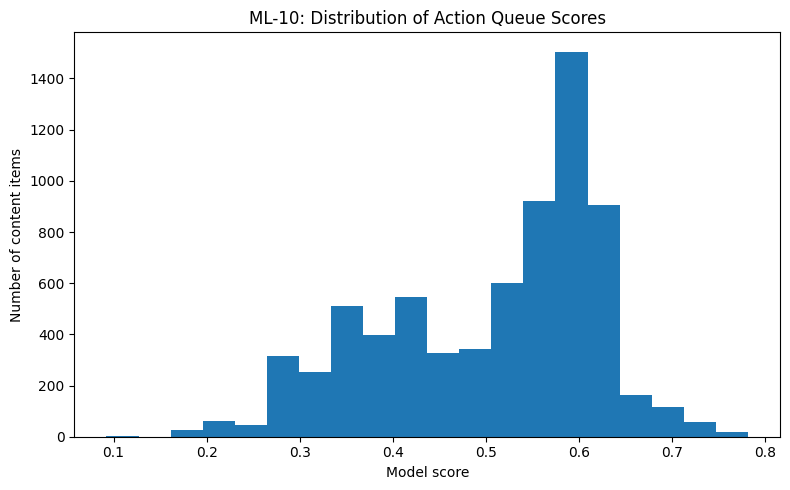

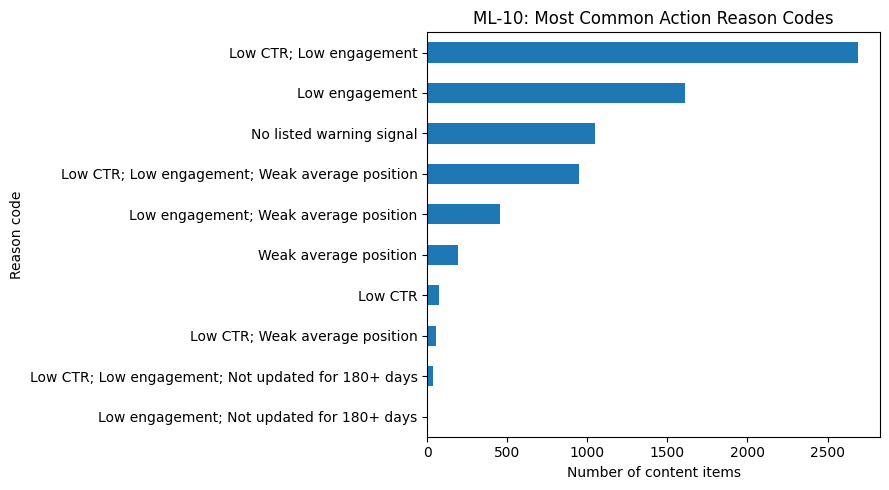

Exports saved:
ml10_monitoring_report.csv
ml10_ranked_action_queue.csv
ml10_reason_codes.png
ml10_score_distribution.png


In [6]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
from pathlib import Path
import matplotlib.pyplot as plt

output_dir = Path("/content/flyrank-ml-workspace2/work/outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Export ranked queue
queue.to_csv(
    output_dir / "ml10_ranked_action_queue.csv",
    index=False
)

# Export monitoring report
monitoring_report.to_csv(
    output_dir / "ml10_monitoring_report.csv",
    index=False
)

# Figure 1: Model score distribution
plt.figure(figsize=(8, 5))
plt.hist(queue["model_score"], bins=20)
plt.xlabel("Model score")
plt.ylabel("Number of content items")
plt.title("ML-10: Distribution of Action Queue Scores")
plt.tight_layout()
plt.savefig(
    output_dir / "ml10_score_distribution.png",
    dpi=150
)
plt.show()

# Figure 2: Top reason codes
reason_counts = (
    queue["reason_codes"]
    .value_counts()
    .head(10)
    .sort_values()
)

plt.figure(figsize=(9, 5))
reason_counts.plot(kind="barh")
plt.xlabel("Number of content items")
plt.ylabel("Reason code")
plt.title("ML-10: Most Common Action Reason Codes")
plt.tight_layout()
plt.savefig(
    output_dir / "ml10_reason_codes.png",
    dpi=150
)
plt.show()

print("Exports saved:")
for file in sorted(output_dir.glob("ml10_*")):
    print(file.name)

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.